#TEKS MANUAL

In [1]:
import pandas as pd
import re

kalimat = [
    "Indonesia hari ini seperti rumah besar yang atapnya bocor di banyak titik, sementara penghuninya sibuk berebut kursi di ruang tamu.",
    "Korupsi merajalela dari tingkat desa sampai istana, hukum tajam ke bawah tapi tumpul ke atas, dan rakyat kecil selalu jadi korban pertama.",
    "Infrastruktur dibangun megah untuk pamer, tapi sekolah rusak, rumah sakit kekurangan obat, dan guru honorer digaji seadanya.",
    "Alamnya kaya raya, tapi kekayaan itu mengalir ke segelintir orang, sementara mayoritas rakyat tetap berjuang bertahan hidup dari hari ke hari.",
]

data = pd.DataFrame({'teks': kalimat})
data['label'] = ['kritik'] * len(kalimat)
data.head()

,teks,label
0,Indonesia hari ini seperti rumah besar yang at...,kritik
1,Korupsi merajalela dari tingkat desa sampai is...,kritik
2,"Infrastruktur dibangun megah untuk pamer, tapi...",kritik
3,"Alamnya kaya raya, tapi kekayaan itu mengalir ...",kritik


#PEMERIKSAAN DATA

In [2]:
print('Ukuran data:', data.shape)
print('Nilai kosong:')
print(data.isna().sum())
print('Jumlah label:')
print(data['label'].value_counts())

Ukuran data: (4, 2)
Nilai kosong:
teks     0
label    0
dtype: int64
Jumlah label:
label
kritik    4
Name: count, dtype: int64


#CASE FOLDING

In [3]:
data['huruf_kecil'] = data['teks'].str.lower()

data['bersih'] = data['huruf_kecil'].str.replace(
    r'[^a-z0-9\s]', ' ', regex=True
)

data['bersih'] = data['bersih'].str.replace(
    r'\s+', ' ', regex=True
)

data['bersih'] = data['bersih'].str.strip()

data[['teks', 'bersih']]

,teks,bersih
0,Indonesia hari ini seperti rumah besar yang at...,indonesia hari ini seperti rumah besar yang at...
1,Korupsi merajalela dari tingkat desa sampai is...,korupsi merajalela dari tingkat desa sampai is...
2,"Infrastruktur dibangun megah untuk pamer, tapi...",infrastruktur dibangun megah untuk pamer tapi ...
3,"Alamnya kaya raya, tapi kekayaan itu mengalir ...",alamnya kaya raya tapi kekayaan itu mengalir k...


#TOKENISASI

In [4]:
contoh = data.loc[0, 'bersih']
token = contoh.split()

print('Teks:', contoh)
print('Token:', token)

Teks: indonesia hari ini seperti rumah besar yang atapnya bocor di banyak titik sementara penghuninya sibuk berebut kursi di ruang tamu
Token: ['indonesia', 'hari', 'ini', 'seperti', 'rumah', 'besar', 'yang', 'atapnya', 'bocor', 'di', 'banyak', 'titik', 'sementara', 'penghuninya', 'sibuk', 'berebut', 'kursi', 'di', 'ruang', 'tamu']


#PENGHAPUSAN STOPWORDS

In [5]:
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory

stopwords = set(StopWordRemoverFactory().get_stop_words())
stopwords = stopwords - {'tidak', 'bukan', 'jangan', 'belum'}

token_penting = []
for kata in token:
    if kata not in stopwords:
        token_penting.append(kata)

print(token_penting)

['indonesia', 'hari', 'rumah', 'besar', 'atapnya', 'bocor', 'banyak', 'titik', 'penghuninya', 'sibuk', 'berebut', 'kursi', 'ruang', 'tamu']


#STEMMING

In [6]:
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory

stemmer = StemmerFactory().create_stemmer()
hasil_stem = [stemmer.stem(kata) for kata in token_penting]

print('Sebelum:', token_penting)
print('Sesudah:', hasil_stem)

Sebelum: ['indonesia', 'hari', 'rumah', 'besar', 'atapnya', 'bocor', 'banyak', 'titik', 'penghuninya', 'sibuk', 'berebut', 'kursi', 'ruang', 'tamu']
Sesudah: ['indonesia', 'hari', 'rumah', 'besar', 'atap', 'bocor', 'banyak', 'titik', 'hun', 'sibuk', 'rebut', 'kursi', 'ruang', 'tamu']


#FREKUENSI KATA

In [7]:
from collections import Counter
import matplotlib.pyplot as plt

semua_kata = ' '.join(data['bersih']).split()
frekuensi = Counter(
    kata for kata in semua_kata if kata not in stopwords
)

print(frekuensi.most_common(10))

[('hari', 3), ('rumah', 2), ('rakyat', 2), ('indonesia', 1), ('besar', 1), ('atapnya', 1), ('bocor', 1), ('banyak', 1), ('titik', 1), ('penghuninya', 1)]


#VISUALISASI DATA

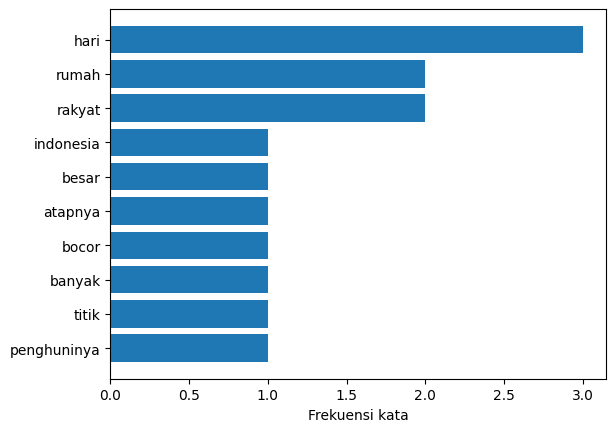

In [8]:
kata, jumlah = zip(*frekuensi.most_common(10))

plt.barh(kata, jumlah)
plt.xlabel('Frekuensi kata')
plt.gca().invert_yaxis()
plt.show()

#Bag of Word dengan CountVectorize

In [9]:
from sklearn.feature_extraction.text import CountVectorizer

dokumen = data['bersih']

count = CountVectorizer()
matriks_count = count.fit_transform(dokumen)

pd.DataFrame(
    matriks_count.toarray(),
    columns=count.get_feature_names_out()
)

,alamnya,atapnya,atas,banyak,bawah,berebut,berjuang,bertahan,besar,bocor,...,sibuk,tajam,tamu,tapi,tetap,tingkat,titik,tumpul,untuk,yang
0,0,1,0,1,0,1,0,0,1,1,...,1,0,1,0,0,0,1,0,0,1
1,0,0,1,0,1,0,0,0,0,0,...,0,1,0,1,0,1,0,1,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,1,0,0,0,0,1,0
3,1,0,0,0,0,0,1,1,0,0,...,0,0,0,1,1,0,0,0,0,0


#TF-IDF dengan TfidfVectorizer

In [10]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer()
matriks_tfidf = tfidf.fit_transform(dokumen)

pd.DataFrame(
    matriks_tfidf.toarray(),
    columns=tfidf.get_feature_names_out()
).round(2)

,alamnya,atapnya,atas,banyak,bawah,berebut,berjuang,bertahan,besar,bocor,...,sibuk,tajam,tamu,tapi,tetap,tingkat,titik,tumpul,untuk,yang
0,0.00,0.22,0.00,0.22,0.00,0.22,0.00,0.00,0.22,0.22,...,0.22,0.00,0.22,0.00,0.00,0.00,0.22,0.00,0.00,0.22
1,0.00,0.00,0.22,0.00,0.22,0.00,0.00,0.00,0.00,0.00,...,0.00,0.22,0.00,0.14,0.00,0.22,0.00,0.22,0.00,0.00
2,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,...,0.00,0.00,0.00,0.16,0.00,0.00,0.00,0.00,0.25,0.00
3,0.22,0.00,0.00,0.00,0.00,0.00,0.22,0.22,0.00,0.00,...,0.00,0.00,0.00,0.14,0.22,0.00,0.00,0.00,0.00,0.00
